# Comparing models for a Fan Out ctRSD circuit

Comparing the modeling results of the TMSE-BioCRNpyler Library to the ctRSD simulator 2.0 (https://ctrsd-simulator.readthedocs.io/en/latest/Overview.html)
- Specifically this example: https://ctrsd-simulator.readthedocs.io/en/latest/Simple-Examples.html#fan-out-fan-in-simulation
- Leak was set to 0 for this comparison as the ctRSD gate leak was handled slightly differently between the two models 


## Dependencies and packages

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
import pandas as pd
from pathlib import Path

import urllib.request
import types
import sys
import warnings

# Ignore specific syntax warnings about invalid escape sequences
warnings.filterwarnings("ignore", category=SyntaxWarning)

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

# ctRSD-simulator repository
# URL to the raw simulator python file on GitHub
url = "https://raw.githubusercontent.com/usnistgov/ctRSD-simulator/main/ctRSD-simulator-2.0/ctRSD_simulator_200.py"

# Download the script into memory
response = urllib.request.urlopen(url)
code = response.read().decode('utf-8')

# Dynamically create a module in memory
rsd_module = types.ModuleType("ctRSD_simulator_200")
exec(code, rsd_module.__dict__)
sys.modules["ctRSD_simulator_200"] = rsd_module

# Import and initialize the simulator normally
import ctRSD_simulator_200 as RSDs

model = RSDs.RSD_sim()
print("Simulator loaded successfully in memory!")

Simulator loaded successfully in memory!


## Global variables and definitions

In [2]:
# Simulate all models - example for 3 hours
timepoints = np.linspace(0,4,5001)*3600 

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (6, 6)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

leak_rate = 0 # ctRSD leak rate to use 

#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 20
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, 
               title_fontsize = fs-5, fontsize=fs-5)

    plt.ylim(ymin,ymax)
    plt.xlim(0,4)
    plt.xticks(ticks=[0,1,2,3,4],fontsize=fs)
    if ymax < 1:
        plt.yticks(ticks=[0.0,0.1,0.2,0.3,0.4,0.5],fontsize=fs)
    else:
        plt.yticks(ticks=[0,2,4,6,8],fontsize=fs)

    # Save plot as svg
    plt.savefig(f'{figs_dir}/validation_ctRSD_{fig_name}.svg')

# TMSE-BioCRNpyler simulation

A simulation of a ctRSD circuits from Design Approaches to Expand the Toolkit for Building Cotranscriptionally Encoded RNA Strand Displacement Circuits ([Schaffter et al. *ACS Synthetic Biology* 2023](https://pubs.acs.org/doi/10.1021/acssynbio.3c00079)). 



In [3]:
# Define initial DNA and Reporter RNA
sim_inputs = {'O{4,3}': ['Output',4,3]} # Input DNA
sim_gates = {'G{3,5}':['Gate',3,5],'G{3,8}':['Gate',3,8],'G{8,2}':['Gate',8,2],'G{5,2}':['Gate',5,2]} # Gate DNA
sim_reporter = {'R{2,}':['Reporter',2]} # Reporter DNA

# Components
step_tx0 = StrandExchangeMol(sim_inputs, material_type= 'dna', transcription=True)
step_tx1 = StrandExchangeMol(sim_gates, material_type= 'dna', transcription=True, rna_maturation=True,leak='ctRSDleak')
step_tx2 =StrandExchangeMol(sim_reporter, material_type = 'dna')

step_mat =RNAmaturation(step_tx1)

rna_TMSE = step_tx0.rna+ step_tx1.rna+ step_tx2.mol+ step_mat.rna
step_sd = TMSE(rna_TMSE)
step_leak = LeakctRSD(step_tx1)

# Reactions
# # Mechanism tx 
mech_tx = mech_tl = SimpleTranscription()
tx_mechanisms = {mech_tx.mechanism_type:mech_tx}
# Mechanism rz
mech_mat = MaturationO1()
mat_mechanisms = {mech_mat.mechanism_type: mech_mat}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}
# Mechanism leak
mech_leak = GateTxLeak()
leak_mechanisms = {mech_leak.mechanism_type:mech_leak}

parameters_ORctRSD = {"ktx":.02,
                      "leak_percentage":leak_rate, 
                      "kmat": 0.00417, 
                      "kx":1e-6, 
                      ParameterKey(mechanism = "one_step_tmse", part_id = "Gate_3_5", name = "kx"):5e-6,
                      ParameterKey(mechanism = "one_step_tmse", part_id = "Gate_5_2", name = "kx"):3e-6,
                      ParameterKey(mechanism = "one_step_tmse", part_id = "Gate_5_2", name = "krev"):1e-8,
                      ParameterKey(mechanism = "one_step_tmse", part_id = "Gate_8_2", name = "krev"):1e-8,
                      "krev":270e-9, 
                      "krep":1e4/1e9
                      }

# Make Mixture and Compile
M_OR = Mixture("IVT_ctRSD", 
               components=[step_tx0.mol, step_tx1.mol, step_mat, step_sd, step_leak],
               parameters=parameters_ORctRSD,
               mechanisms=tx_mechanisms|mat_mechanisms|sd_mechanisms|leak_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_OR = M_OR.compile_crn()

print(CRN_OR.pretty_print(show_rates = True, show_attributes = True,
                          show_materials = True, show_keys = True))

[rna_Output_3_5_dummy, rna_Output_3_8_dummy, rna_Output_8_2_dummy, rna_Output_5_2_dummy]
Species(N = 28) = {
dna[Signal_2(ss)] (@ 0),  dna[Reporter_2] (@ 0),  rnadna[ReporterOut_2] (@ 0),  rna[Output_8_2] (@ 0),  rna[Output_8_2(dummy)] (@ 0),  rna[Output_5_2] (@ 0),  rna[Output_5_2(dummy)] (@ 0),  rna[Output_4_3] (@ 0),  dna[Output_4_3] (@ 0),  rna[Output_3_8] (@ 0),  rna[Output_3_8(dummy)] (@ 0),  rna[Output_3_5] (@ 0),  rna[Output_3_5(dummy)] (@ 0),  rna[Gate_8_2] (@ 0),  rna[Gate_8_2(pre)] (@ 0),  dna[Gate_8_2] (@ 0),  rna[Gate_5_2] (@ 0),  rna[Gate_5_2(pre)] (@ 0),  dna[Gate_5_2] (@ 0),  rna[Gate_3_8] (@ 0),  rna[Gate_3_8(pre)] (@ 0),  dna[Gate_3_8] (@ 0),  rna[Gate_3_5] (@ 0),  rna[Gate_3_5(pre)] (@ 0),  dna[Gate_3_5] (@ 0),  rna[GateOut_4_3] (@ 0),  rna[GateOut_3_8] (@ 0),  rna[GateOut_3_5] (@ 0),  
}

Reactions (17) = [
0. dna[Output_4_3] --> dna[Output_4_3]+rna[Output_4_3]
 Kf=k_forward * dna_Output_4_3
  k_forward=0.02
  found_key=(mech=None, partid=None, name=ktx).
  search_k

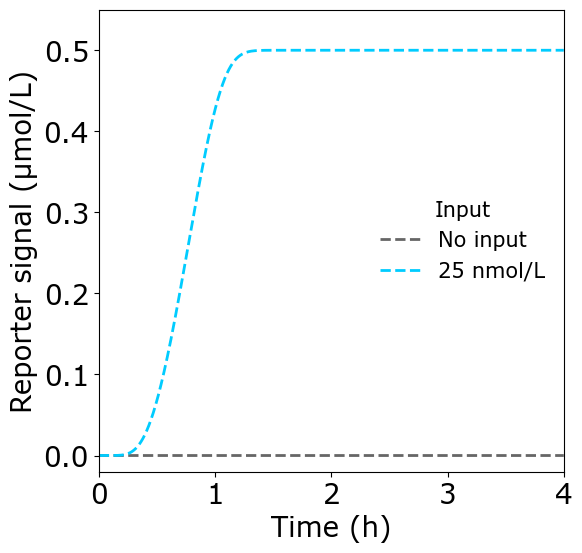

In [4]:
# Simulate
try:
    import pylab as plt

    # Input templates
    IN = [0,25]

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '25 nmol/L': [[0,0.8,1],'--']}

    cnt = 0
    for I_conc, key in zip(IN, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'dna_Output_4_3': I_conc,
                                      'dna_Gate_3_5':15,
                                      'dna_Gate_3_8':15,
                                      'dna_Gate_8_2':10,
                                      'dna_Gate_5_2':10,
                                      'dna_Reporter_2':500}
        
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_OR.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                    initial_condition_dict = initial_concentration_dict)
        
        S2 = R['dna_Signal_2_ss']
        O3 = R['rna_Output_4_3']
        G5 = R['rna_Gate_3_5']
        G8 = R['rna_Gate_3_8']
        G52 = R['rna_Gate_5_2']
        G82 = R['rna_Gate_8_2']
        O5 = R['rna_Output_3_5']
        O8 = R['rna_Output_3_8']
        O52 = R['rna_Output_5_2']
        O82 = R['rna_Output_8_2']

        # saving model data
        data_array = {'time': timepoints, 'S2': S2, 'O3': O3, 'G5': G5, 'G8': G8, 'G52': G52, 'G82': G82, 'O5': O5, 'O8': O8, 'O52': O52, 'O82': O82}
        df = pd.DataFrame(data=data_array)
        df.to_csv(f'{data_dir}/validation_BioCRNpyler_FanInFanOutIVT_{str(cnt)}.csv',index=False)

        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_2_ss']/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])

        cnt += 1
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reporter signal (μmol/L)',ymax = 0.55, fig_name= 'FanInFanOutIVT_BioCRNpyler')   

# ctRSD-simulator-2.1.0 simulation

A simulation of a ctRSD circuits from Design Approaches to Expand the Toolkit for Building Cotranscriptionally Encoded RNA Strand Displacement Circuits ([Schaffter et al. *ACS Synthetic Biology* 2023](https://pubs.acs.org/doi/10.1021/acssynbio.3c00079)). 

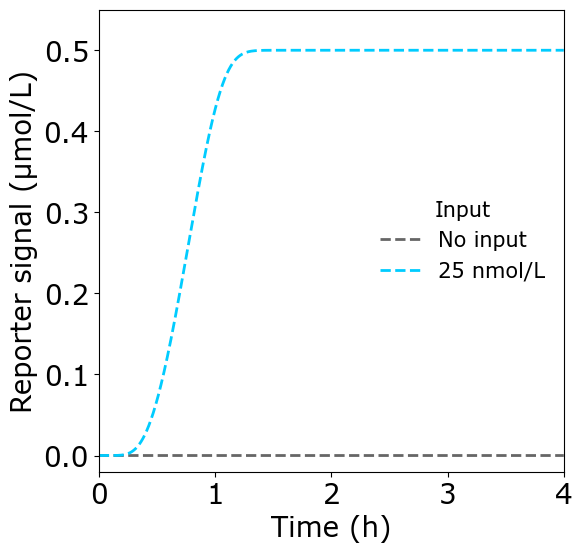

In [5]:

REP_con = 500 #reporter concentration

t_sim = timepoints

model = RSDs.RSD_sim(8) # define the model instance

# specify species involved in the reaction 

model.global_rate_constants(ktxn=0.02)
model.molecular_species('G{3,5}',DNA_con=15,krev=270/1e9,leak=leak_rate,krsd=5e-6)
model.molecular_species('G{3,8}',DNA_con=15,krev=270/1e9,leak=leak_rate)
model.molecular_species('G{5,2}',DNA_con=10,krev=1e-8,leak=leak_rate,krsd=3e-6)
model.molecular_species('G{8,2}',DNA_con=10,krev=1e-8,leak=leak_rate)
model.molecular_species('R{2}',ic=REP_con)

try:
    import pylab as plt

    # Input templates
    IN = [0,25]

    idx_conditions = {'No input':[[0.4,0.4,0.4], '--'],
                      '25 nmol/L': [[0,0.8,1],'--']}
    cnt = 0
    for I_conc, key in zip(IN, idx_conditions.keys()):
        model.molecular_species('O{4,3}',DNA_con=I_conc)
    
        # simulate the model (input is simulation time)
        model.simulate(t_sim)
        
        # pull out the species from the model solution to plot
        S2 = model.output_concentration('S{2}')
        O3 = model.output_concentration('O{4,3}')
        G5 = model.output_concentration('G{3,5}')
        G8 = model.output_concentration('G{3,8}')
        G52 = model.output_concentration('G{5,2}')
        G82 = model.output_concentration('G{8,2}')
        O5 = model.output_concentration('O{3,5}')
        O8 = model.output_concentration('O{3,8}')
        O52 = model.output_concentration('O{5,2}')
        O82 = model.output_concentration('O{8,2}')

        # saving model data
        data_array = {'time': timepoints, 'S2': S2, 'O3': O3, 'G5': G5, 'G8': G8, 'G52': G52, 'G82': G82, 'O5': O5, 'O8': O8, 'O52': O52, 'O82': O82}
        df = pd.DataFrame(data=data_array)
        df.to_csv(f'{data_dir}/validation_ctRSDsim_FanInFanOutIVT_{str(cnt)}.csv',index=False)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(model.t/3600, S2/1000, label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])
  
        cnt += 1
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

FormatPlot(ylabel='Reporter signal (μmol/L)',ymax = 0.55, fig_name= 'FanInFanOutIVT_ctRSDsim')   

Computing the relative error between the two models

<Figure size 1925x925 with 0 Axes>

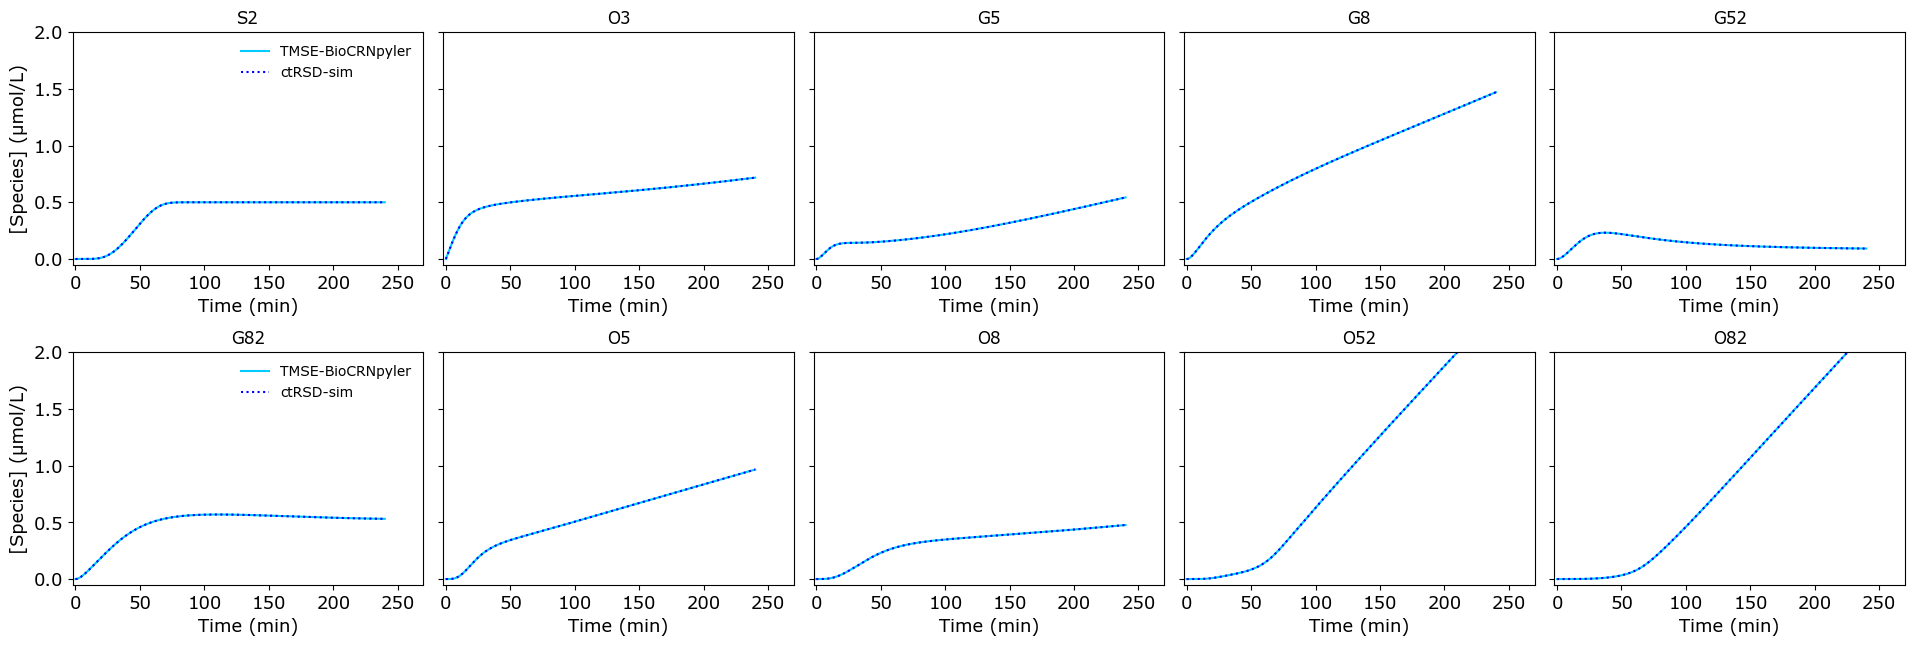

In [6]:
num_conds = 2 # number of input conditions
num_vars = 10 # number of state variables for comparison
if leak_rate == 0:
    start_cond = 1
else:
    start_cond = 0
line_colors = [[0.5,0.5,0.5],
               [0,0.8,1]]
line_colors2 = [[0.25,0.25,0.25],
               [0,0,1]]
figW = 19.25 # figure width
figH = 9.25 # figure height
fs = 13
plt.figure(1, figsize=(figW, figH))
plt.figure(2, figsize=(figW, figH))

cut_off = 60*5 # number of seconds at which to begin the relative error analysis
max_rel_err = np.zeros([2,num_vars]) # array to store the max relative errors for each of the species

for n in range(start_cond,num_conds):

    ctRSDsim_df = pd.read_csv(f'{data_dir}/validation_ctRSDsim_FanInFanOutIVT_'+str(n)+'.csv')
    BioCRNpyler_df = pd.read_csv(f'{data_dir}/validation_BioCRNpyler_FanInFanOutIVT_'+str(n)+'.csv')
   
    col_var = ctRSDsim_df.columns.to_list()

    for m in range(1,num_vars+1):

        ctRSDsim_df['rel_err (%)-'+col_var[m]] = 100*abs(BioCRNpyler_df[col_var[m]] - ctRSDsim_df[col_var[m]])/BioCRNpyler_df[col_var[m]]
        BioCRNpyler_df['rel_err (%)-'+col_var[m]] = 100*abs(ctRSDsim_df[col_var[m]] - BioCRNpyler_df[col_var[m]])/ctRSDsim_df[col_var[m]]

        max_rel_err[0,m-1] = max(ctRSDsim_df.loc[ctRSDsim_df['time']>cut_off,'rel_err (%)-'+col_var[m]])
        max_rel_err[1,m-1] = max(BioCRNpyler_df.loc[BioCRNpyler_df['time']>cut_off,'rel_err (%)-'+col_var[m]])
        
        plt.figure(1)
        plt.subplot(3,5,m)
        plt.title(col_var[m])
        
        # Plotting data 
        plt.plot(ctRSDsim_df['time']/60,ctRSDsim_df[col_var[m]]/1000,color=line_colors[n])
        plt.plot(BioCRNpyler_df['time']/60,BioCRNpyler_df[col_var[m]]/1000,color=line_colors2[n],linestyle=':')
        plt.ylim(-0.05,2)
        plt.xlabel('Time (min)',fontsize=fs)
        if m == 1 or m == 6: 
            plt.ylabel('[Species] (μmol/L)',fontsize=fs)
            plt.legend(['TMSE-BioCRNpyler','ctRSD-sim'],frameon=False)
        else:
            ax1 = plt.gca()
            ax1.yaxis.set_ticklabels([])
        plt.xticks(fontsize=fs)
        plt.yticks(fontsize=fs)
        plt.xlim([-2,270])
        
        '''
        plt.figure(2)
        plt.subplot(3,5,m)
        # Plotting relative error
        plt.plot(ctRSDsim_df['time']/60,ctRSDsim_df['rel_err (%)-'+col_var[m]],color=line_colors[n])
        plt.plot(BioCRNpyler_df['time']/60,BioCRNpyler_df['rel_err (%)-'+col_var[m]],color=line_colors2[n],linestyle=':')
        plt.ylim(-0.005,0.18)
        plt.xlabel('Time (min)',fontsize=fs)
        if m == 1 or m == 6: 
            plt.ylabel('Relative error (%)',fontsize=fs)
            plt.legend(['TMSE-BioCRNpyler','ctRSD-sim'],frameon=False)
        else:
            ax1 = plt.gca()
            ax1.yaxis.set_ticklabels([])
        plt.xticks(fontsize=fs)
        plt.yticks(fontsize=fs)
        plt.xlim([-2,270])
        '''
    
    ctRSDsim_df.to_csv(f'{data_dir}/validation_ctRSDsim_FanInFanOutIVT_{str(n)}.csv',index=False)
    BioCRNpyler_df.to_csv(f'{data_dir}/validation_BioCRNpyler_FanInFanOutIVT_{str(n)}.csv',index=False)

# Save plot as svg
plt.tight_layout(h_pad=1.0) 
plt.savefig(f'{figs_dir}/validation_ctRSD_FanInFanOutIVT_sim_cmp.svg')

# Computing environment

In [7]:
# Computing environment
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

